# Análise Comparativa de Ações com Python e Pandas

## Objetivo do projeto

Este projeto tem como objetivo analisar e comparar o desempenho histórico de três ações da bolsa brasileira: BBSE3, ITSA4 e VALE3, utilizando Python, Pandas e dados financeiros obtidos por meio da biblioteca yfinance.

Serão analisados indicadores como preços de fechamento, rentabilidade acumulada, volatilidade e desempenho comparativo ao longo de um período de 12 meses.

## 1. Importação das bibliotecas

Nesta etapa, são importadas as bibliotecas utilizadas no desenvolvimento do projeto:

- **Pandas:** manipulação e análise dos dados.
- **yfinance:** obtenção de dados históricos do mercado financeiro.
- **Matplotlib:** criação de gráficos para visualização dos resultados.

In [450]:
import pandas as pd
import matplotlib.pyplot as plt


In [451]:
ativos = ["BBSE3.SA", "ITSA4.SA", "VALE3.SA"]

## 2. Coleta dos dados

Nesta etapa, foram selecionados três ativos da bolsa brasileira: BBSE3, ITSA4 e VALE3.

Os dados históricos foram obtidos por meio da biblioteca yfinance, considerando um período de 12 meses e uma frequência diária de negociação.

In [452]:
dados = pd.read_csv(
    "dados_acoes.csv",
    header=[0, 1],
    index_col=0,
    parse_dates=True
)

In [453]:
dados.head()

Price           Close                             High                        \
Ticker       BBSE3.SA   ITSA4.SA   VALE3.SA   BBSE3.SA   ITSA4.SA   VALE3.SA   
Date                                                                           
2025-11-17  29.987257  10.648161  60.283913  30.182153  10.701760  60.792282   
2025-11-18  29.668341  10.576697  60.099045  29.987257  10.639228  60.348614   
2025-11-19  29.517736  10.496299  60.034344  29.863232  10.585630  60.320887   
2025-11-21  29.473444  10.523099  60.228458  29.659479  10.558831  60.330127   
2025-11-24  29.730352  10.549898  60.163750  29.854376  10.630295  60.561206   

Price             Low                             Open                        \
Ticker       BBSE3.SA   ITSA4.SA   VALE3.SA   BBSE3.SA   ITSA4.SA   VALE3.SA   
Date                                                                           
2025-11-17  29.801222  10.558831  59.997377  29.934106  10.683893  60.635150   
2025-11-18  29.668341  10.505233  59.433543  29.987257  10.585630  59.572185   
2025-11-19  29.517736  10.478434  59.803265  29.677196  10.540965  60.099046   
2025-11-21  29.313984  10.433769  59.276407  29.544313  10.532032  59.664625   
2025-11-24  29.393715  10.487366  59.877214  29.473445  10.514166  60.089810   

Price        Volume                      
Ticker     BBSE3.SA  ITSA4.SA  VALE3.SA  
Date                                     
2025-11-17  7390400  21341154  20150800  
2025-11-18  2738600  26245518  22468700  
2025-11-19  2731600  20450286  16523800  
2025-11-21  3665600  17075106  20272600  
2025-11-24  5437600  27442794  20462800

## Análise exploratória

In [454]:
dados.shape
dados.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 248 entries, 2025-11-17 to 2026-11-17
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   (Close, BBSE3.SA)   248 non-null    float64
 1   (Close, ITSA4.SA)   248 non-null    float64
 2   (Close, VALE3.SA)   248 non-null    float64
 3   (High, BBSE3.SA)    248 non-null    float64
 4   (High, ITSA4.SA)    248 non-null    float64
 5   (High, VALE3.SA)    248 non-null    float64
 6   (Low, BBSE3.SA)     248 non-null    float64
 7   (Low, ITSA4.SA)     248 non-null    float64
 8   (Low, VALE3.SA)     248 non-null    float64
 9   (Open, BBSE3.SA)    248 non-null    float64
 10  (Open, ITSA4.SA)    248 non-null    float64
 11  (Open, VALE3.SA)    248 non-null    float64
 12  (Volume, BBSE3.SA)  248 non-null    int64  
 13  (Volume, ITSA4.SA)  248 non-null    int64  
 14  (Volume, VALE3.SA)  248 non-null    int64  
dtypes: float64(12), int64(3)
memory usage:

In [455]:
dados.isnull().sum()

Price   Ticker  
Close   BBSE3.SA    0
        ITSA4.SA    0
        VALE3.SA    0
High    BBSE3.SA    0
        ITSA4.SA    0
        VALE3.SA    0
Low     BBSE3.SA    0
        ITSA4.SA    0
        VALE3.SA    0
Open    BBSE3.SA    0
        ITSA4.SA    0
        VALE3.SA    0
Volume  BBSE3.SA    0
        ITSA4.SA    0
        VALE3.SA    0
dtype: int64

In [456]:
fechamento = dados["Close"]
display(fechamento.head())

Ticker,BBSE3.SA,ITSA4.SA,VALE3.SA
Date,,,
2025-11-17,29.987257,10.648161,60.283913
2025-11-18,29.668341,10.576697,60.099045
2025-11-19,29.517736,10.496299,60.034344
2025-11-21,29.473444,10.523099,60.228458
2025-11-24,29.730352,10.549898,60.163750


In [457]:
fechamento.describe()

Ticker,BBSE3.SA,ITSA4.SA,VALE3.SA
count,248.000000,248.000000,248.000000
mean,35.421371,13.198255,74.735129
std,3.669916,1.196259,7.033015
min,29.473444,10.496299,60.034344
25%,32.596371,12.629989,70.701757
50%,33.738132,13.307287,75.798061
75%,38.792500,13.900097,79.878567
max,43.680000,16.540001,87.631020


In [458]:
preco_inicial = fechamento.iloc[0]
display(preco_inicial)

Ticker
BBSE3.SA    29.987257
ITSA4.SA    10.648161
VALE3.SA    60.283913
Name: 2025-11-17 00:00:00, dtype: float64

In [459]:
preco_final = fechamento.iloc[-1]
display(preco_final)

Ticker
BBSE3.SA    37.279999
ITSA4.SA    13.300000
VALE3.SA    60.340000
Name: 2026-11-17 00:00:00, dtype: float64

In [460]:
rentabilidade = (preco_final / preco_inicial - 1) * 100
display(rentabilidade)

Ticker
BBSE3.SA    24.319469
ITSA4.SA    24.904200
VALE3.SA     0.093039
dtype: float64

In [461]:
melhor_acao = rentabilidade.idxmax()
display(melhor_acao)
pior_acao = rentabilidade.idxmin()
display(pior_acao)

'ITSA4.SA'

'VALE3.SA'

In [462]:
retornos_diarios = fechamento.pct_change()
display(retornos_diarios.head())

Ticker,BBSE3.SA,ITSA4.SA,VALE3.SA
Date,,,
2025-11-17,NaN,NaN,NaN
2025-11-18,-0.010635,-0.006711,-0.003067
2025-11-19,-0.005076,-0.007601,-0.001077
2025-11-21,-0.001501,0.002553,0.003233
2025-11-24,0.008717,0.002547,-0.001074


In [463]:
volatilidade_diaria = retornos_diarios.std()
display(volatilidade_diaria)

Ticker
BBSE3.SA    0.014381
ITSA4.SA    0.019636
VALE3.SA    0.018200
dtype: float64

In [464]:
volatilidade_anual = volatilidade_diaria * (252 ** 0.5)
display(volatilidade_anual * 100)

Ticker
BBSE3.SA    22.828552
ITSA4.SA    31.170408
VALE3.SA    28.890883
dtype: float64

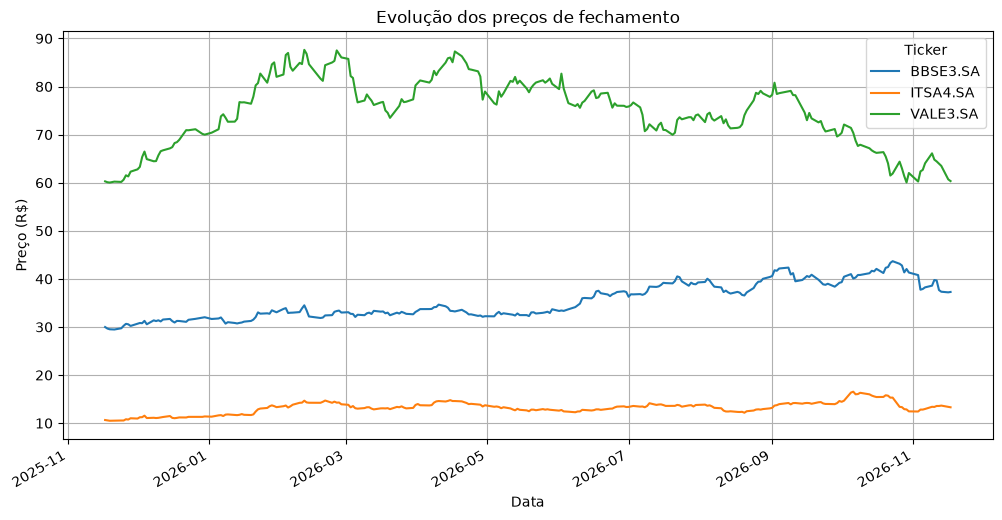

In [465]:
fechamento.plot(figsize=(12, 6))

plt.title("Evolução dos preços de fechamento")
plt.xlabel("Data")
plt.ylabel("Preço (R$)")
plt.grid()
plt.show()

In [466]:
precos_normalizados = (fechamento / fechamento.iloc[0] * 100)
display(precos_normalizados.head())

Ticker,BBSE3.SA,ITSA4.SA,VALE3.SA
Date,,,
2025-11-17,100.000000,100.000000,100.000000
2025-11-18,98.936494,99.328865,99.693338
2025-11-19,98.434266,98.573818,99.586011
2025-11-21,98.286562,98.825506,99.908012
2025-11-24,99.143287,99.077185,99.800672


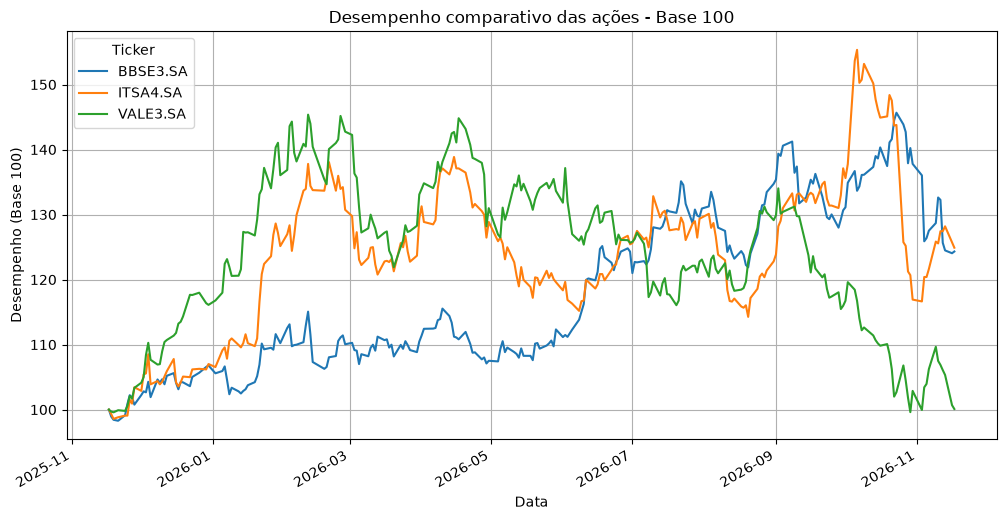

In [467]:
precos_normalizados.plot(figsize=(12, 6))

plt.title("Desempenho comparativo das ações - Base 100")
plt.xlabel("Data")
plt.ylabel("Desempenho (Base 100)")
plt.grid()
plt.show()

In [468]:
display(precos_normalizados.tail())

Ticker,BBSE3.SA,ITSA4.SA,VALE3.SA
Date,,,
2026-11-11,132.256177,127.439844,106.877602
2026-11-12,125.653374,127.439844,106.081371
2026-11-13,124.486217,128.191147,105.334901
2026-11-16,124.052696,125.749417,100.690214
2026-11-17,124.319469,124.904200,100.093039


In [469]:
preco_maximo = fechamento.max()
preco_minimo = fechamento.min()
display(preco_maximo)
display(preco_minimo)

Ticker
BBSE3.SA    43.680000
ITSA4.SA    16.540001
VALE3.SA    87.631020
dtype: float64

Ticker
BBSE3.SA    29.473444
ITSA4.SA    10.496299
VALE3.SA    60.034344
dtype: float64

In [470]:
indicadores = pd.DataFrame({
    "Preço Inicial": preco_inicial,
    "Preço Final": preco_final,
    "Preço Máximo": preco_maximo,
    "Preço Mínimo": preco_minimo,
    "Rentabilidade (%)": rentabilidade,
    "Volatilidade Anual (%)": volatilidade_anual * 100
})

display(indicadores)

,Preço Inicial,Preço Final,Preço Máximo,Preço Mínimo,Rentabilidade (%),Volatilidade Anual (%)
Ticker,,,,,,
BBSE3.SA,29.987257,37.279999,43.680000,29.473444,24.319469,22.828552
ITSA4.SA,10.648161,13.300000,16.540001,10.496299,24.904200,31.170408
VALE3.SA,60.283913,60.340000,87.631020,60.034344,0.093039,28.890883


In [471]:
retorno_por_volatilidade = (
    rentabilidade / (volatilidade_anual * 100)
)

display(retorno_por_volatilidade)

Ticker
BBSE3.SA    1.065309
ITSA4.SA    0.798969
VALE3.SA    0.003220
dtype: float64

## Resultados e conclusão

## Conclusão

A ITSA4 apresentou a maior rentabilidade no período, de 24,90%, mas também a maior volatilidade anualizada, de 31,17%.

A BBSE3 registrou rentabilidade de 24,32% e a menor volatilidade, de 22,83%, destacando-se pelo equilíbrio entre retorno e risco.

Já a VALE3 apresentou a menor rentabilidade, de 0,09%, com volatilidade anualizada de 28,89%.

Portanto, a ITSA4 se destacou pela maior rentabilidade, enquanto a BBSE3 apresentou a melhor relação risco-retorno entre os ativos analisados.